# 01b – Single-Qubit Gates and the Bloch Sphere

This notebook provides a rigorous pedagogical review of single-qubit quantum gates, their mathematical representation as $2 \times 2$ unitary matrices, statevector transformations on the Bloch sphere, and their connection to the Quantum Approximate Optimization Algorithm (QAOA).

For every experiment:
1. We present the mathematical definition of the gate matrix and its operation on statevectors.
2. We include an analytical **Prediction Check** deriving exact expected measurement probabilities.
3. We execute code that computes the exact `Statevector` side-by-side with 4096-shot `AerSimulator` sampling (`seed_simulator=42`).

## 1. Setup & Helper Function: `inspect_gate`

To inspect quantum circuits systematically, we define `inspect_gate(qc, shots=4096, seed=42)`:
- Computes the exact statevector amplitudes and analytical measurement probabilities via `Statevector(qc).probabilities_dict()`.
- Executes measurement sampling using `AerSimulator(seed_simulator=seed)` with 4096 shots.
- Formats a side-by-side table comparing analytical vs. empirical probabilities.

In [1]:
# Setup: Imports and inspect_gate helper
import numpy as np
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import Statevector
from qiskit.visualization import plot_bloch_multivector
from qiskit_aer import AerSimulator

# Fix random seed for reproducibility
np.random.seed(42)

def inspect_gate(qc, shots=4096, seed=42):
    """
    Computes exact Statevector, exact probabilities, and runs Aer simulation with measurement.
    Compares analytical vs. sampled probabilities side-by-side.
    """
    # 1. Exact Statevector (evaluated before adding measurement gates)
    sv = Statevector(qc)
    exact_probs = sv.probabilities_dict()
    
    # 2. Aer simulation with measurement
    qc_meas = qc.copy()
    qc_meas.measure_all()
    sim = AerSimulator(seed_simulator=seed)
    transpiled_qc = transpile(qc_meas, sim)
    result = sim.run(transpiled_qc, shots=shots).result()
    counts = result.get_counts()
    
    # 3. Print side-by-side comparison table
    all_states = sorted(set(list(exact_probs.keys()) + list(counts.keys())))
    print("Exact Statevector amplitudes:")
    for i, amp in enumerate(sv.data):
        print(f"  |{i}>: {amp.real:+.4f} + {amp.imag:+.4f}j  (|amp|: {abs(amp):.4f})")
    
    print(f"\n{'State':<8} | {'Exact Prob':<12} | {'Sampled Prob (' + str(shots) + ')':<22} | {'Diff':<10}")
    print("-" * 58)
    for s in all_states:
        ep = exact_probs.get(s, 0.0)
        sp = counts.get(s, 0) / shots
        print(f"|{s}>    | {ep:<12.4f} | {sp:<22.4f} | {abs(ep - sp):<10.4f}")
    
    return sv, counts

## 2. Group A — Pauli & Hadamard Gates (X, Z, H)

### Experiment A1: Pauli X Gate (Bit Flip)
**Mathematical Definition:**
The Pauli $X$ operator is defined as:
$$X = \begin{pmatrix} 0 & 1 \\ 1 & 0 \end{pmatrix}$$
Its action on computational basis states $|0\rangle = \begin{pmatrix} 1 \\ 0 \end{pmatrix}$ and $|1\rangle = \begin{pmatrix} 0 \\ 1 \end{pmatrix}$ is:
$$X|0\rangle = \begin{pmatrix} 0 & 1 \\ 1 & 0 \end{pmatrix} \begin{pmatrix} 1 \\ 0 \end{pmatrix} = \begin{pmatrix} 0 \\ 1 \end{pmatrix} = |1\rangle$$
$$X|1\rangle = \begin{pmatrix} 0 & 1 \\ 1 & 0 \end{pmatrix} \begin{pmatrix} 0 \\ 1 \end{pmatrix} = \begin{pmatrix} 1 \\ 0 \end{pmatrix} = |0\rangle$$
On the Bloch sphere, $X$ corresponds to a rotation of $\pi$ radians ($180^\circ$) around the X-axis, flipping the state vector from the North Pole ($|0\rangle$) to the South Pole ($|1\rangle$).

**Prediction Check:**
Starting from $|0\rangle$:
- Analytical statevector: $|\psi\rangle = |1\rangle = \begin{pmatrix} 0 \\ 1 \end{pmatrix}$
- Exact analytical probabilities:
  - $P(|0\rangle) = |\langle 0|\psi\rangle|^2 = 0.0$ ($0\%$)
  - $P(|1\rangle) = |\langle 1|\psi\rangle|^2 = 1.0$ ($100\%$)
- 4096-shot Aer simulation expectation: Deterministically 4096 counts for `'1'` and 0 counts for `'0'`.

In [2]:
# Experiment A1: Pauli X on |0>
qc_x = QuantumCircuit(1)
qc_x.x(0)  # Apply Pauli X gate to flip |0> -> |1>

print("=== Experiment A1: Pauli X on |0> ===")
sv_x, counts_x = inspect_gate(qc_x)

# Pedagogical check: verify exact output
assert counts_x.get('1', 0) == 4096, "X gate on |0> must deterministically yield |1>"
print("Experiment A1 Check: PASS (100% |1>)")

=== Experiment A1: Pauli X on |0> ===
Exact Statevector amplitudes:
  |0>: +0.0000 + +0.0000j  (|amp|: 0.0000)
  |1>: +1.0000 + +0.0000j  (|amp|: 1.0000)

State    | Exact Prob   | Sampled Prob (4096)    | Diff      
----------------------------------------------------------
|1>    | 1.0000       | 1.0000                 | 0.0000    
Experiment A1 Check: PASS (100% |1>)


### Experiment A2: Hadamard Gate (Superposition Creation)
**Mathematical Definition:**
The Hadamard gate $H$ creates an unbiased quantum superposition from computational basis states:
$$H = \frac{1}{\sqrt{2}}\begin{pmatrix} 1 & 1 \\ 1 & -1 \end{pmatrix}$$
Applying $H$ to basis state $|0\rangle$:
$$H|0\rangle = \frac{1}{\sqrt{2}}\begin{pmatrix} 1 & 1 \\ 1 & -1 \end{pmatrix}\begin{pmatrix} 1 \\ 0 \end{pmatrix} = \frac{1}{\sqrt{2}}\begin{pmatrix} 1 \\ 1 \end{pmatrix} = \frac{|0\rangle + |1\rangle}{\sqrt{2}} \equiv |+\rangle$$
Geometrically, $H$ is a $\pi$ rotation around the diagonal $(X+Z)/\sqrt{2}$ axis of the Bloch sphere, mapping the North Pole ($|0\rangle$, Z-axis) to the positive X-axis ($|+\rangle$).

**Prediction Check:**
Starting from $|0\rangle$:
- Analytical statevector: $|\psi\rangle = |+\rangle = \frac{1}{\sqrt{2}}|0\rangle + \frac{1}{\sqrt{2}}|1\rangle$
- Exact analytical probabilities:
  - $P(|0\rangle) = |1/\sqrt{2}|^2 = 0.5$ ($50\%$)
  - $P(|1\rangle) = |1/\sqrt{2}|^2 = 0.5$ ($50\%$)
- 4096-shot Aer simulation expectation: $\approx 2048$ counts for `'0'` and $\approx 2048$ counts for `'1'`.

In [3]:
# Experiment A2: Hadamard H on |0>
qc_h = QuantumCircuit(1)
qc_h.h(0)  # Apply Hadamard gate to create equal superposition |+>

print("=== Experiment A2: Hadamard H on |0> ===")
sv_h, counts_h = inspect_gate(qc_h)

# Pedagogical check: verify 50/50 probability distribution within 3 sigma (~96 shots)
assert abs(counts_h.get('0', 0) - 2048) < 150, "Sampled counts for '0' should be near 2048"
assert abs(counts_h.get('1', 0) - 2048) < 150, "Sampled counts for '1' should be near 2048"
print("Experiment A2 Check: PASS (~50/50 superposition verified)")

=== Experiment A2: Hadamard H on |0> ===
Exact Statevector amplitudes:
  |0>: +0.7071 + +0.0000j  (|amp|: 0.7071)
  |1>: +0.7071 + +0.0000j  (|amp|: 0.7071)

State    | Exact Prob   | Sampled Prob (4096)    | Diff      
----------------------------------------------------------
|0>    | 0.5000       | 0.4937                 | 0.0063    
|1>    | 0.5000       | 0.5063                 | 0.0063    
Experiment A2 Check: PASS (~50/50 superposition verified)


### Experiment A3: Pauli Z Gate and Phase vs. Bit Flip ($HZH = X$)
**Mathematical Definition:**
The Pauli $Z$ gate leaves $|0\rangle$ unchanged and negates the amplitude of $|1\rangle$:
$$Z = \begin{pmatrix} 1 & 0 \\ 0 & -1 \end{pmatrix}$$
$$Z|0\rangle = |0\rangle, \quad Z|1\rangle = -|1\rangle$$
When applied to $|0\rangle$, $Z$ imparts a trivial global phase: $Z|0\rangle = |0\rangle$.
When applied to $|+\rangle = \frac{|0\rangle + |1\rangle}{\sqrt{2}}$, $Z$ introduces a relative phase of $\pi$ ($e^{i\pi} = -1$):
$$Z|+\rangle = \frac{|0\rangle - |1\rangle}{\sqrt{2}} \equiv |-\rangle$$

**Why $|+\rangle$ and $|-\rangle$ Both Yield 50/50 in Standard Z-Basis Measurement:**
Projective measurement in the computational (Z) basis evaluates the squared magnitudes of the projections onto $|0\rangle$ and $|1\rangle$:
- For $|+\rangle$: $P(|0\rangle) = |\langle 0|+\rangle|^2 = \left|\frac{1}{\sqrt{2}}\right|^2 = 0.5$, $\quad P(|1\rangle) = |\langle 1|+\rangle|^2 = \left|\frac{1}{\sqrt{2}}\right|^2 = 0.5$
- For $|-\rangle$: $P(|0\rangle) = |\langle 0|-\rangle|^2 = \left|\frac{1}{\sqrt{2}}\right|^2 = 0.5$, $\quad P(|1\rangle) = |\langle 1|-\rangle|^2 = \left|-\frac{1}{\sqrt{2}}\right|^2 = 0.5$
Because measurement probability is the squared modulus $|\cdot|^2$, the relative phase $e^{i\pi} = -1$ is completely unobservable in standard Z-basis measurement! Both states register identical 50/50 statistics.

**Interferometry & Converting Phase Flip to Bit Flip ($HZH = X$):**
To detect and measure relative phases, we rotate the measurement basis into the X-basis using Hadamard gates:
$$HZH = \frac{1}{\sqrt{2}}\begin{pmatrix} 1 & 1 \\ 1 & -1 \end{pmatrix} \begin{pmatrix} 1 & 0 \\ 0 & -1 \end{pmatrix} \frac{1}{\sqrt{2}}\begin{pmatrix} 1 & 1 \\ 1 & -1 \end{pmatrix} = \begin{pmatrix} 0 & 1 \\ 1 & 0 \end{pmatrix} = X$$
Tracking the state evolution:
$$|0\rangle \xrightarrow{H} |+\rangle = \frac{|0\rangle + |1\rangle}{\sqrt{2}} \xrightarrow{Z} |-\rangle = \frac{|0\rangle - |1\rangle}{\sqrt{2}} \xrightarrow{H} |1\rangle$$
The final Hadamard gate causes destructive interference on $|0\rangle$ and constructive interference on $|1\rangle$:
$$H|-\rangle = \frac{H|0\rangle - H|1\rangle}{\sqrt{2}} = \frac{\frac{|0\rangle+|1\rangle}{\sqrt{2}} - \frac{|0\rangle-|1\rangle}{\sqrt{2}}}{\sqrt{2}} = \frac{2|1\rangle}{2} = |1\rangle$$
The relative phase flip has been deterministically converted into an observable bit flip!

**Prediction Check:**
1. **$Z$ on $|0\rangle$:** Exact state $|0\rangle \implies P(0)=1.0, P(1)=0.0$.
2. **$H \to Z$ on $|0\rangle$:** Exact state $|-\rangle \implies P(0)=0.5, P(1)=0.5$.
3. **$H \to Z \to H$ on $|0\rangle$:** Exact state $|1\rangle \implies P(0)=0.0, P(1)=1.0$ (deterministic bit flip).

In [4]:
# Experiment A3a: Z on |0> (Phase gate on computational zero)
qc_z = QuantumCircuit(1)
qc_z.z(0)
print("=== Experiment A3a: Z on |0> ===")
sv_z, counts_z = inspect_gate(qc_z)

# Experiment A3b: H -> Z on |0> (Creating |-> state)
qc_hz = QuantumCircuit(1)
qc_hz.h(0)
qc_hz.z(0)
print("\n=== Experiment A3b: H -> Z on |0> (|-> state) ===")
sv_hz, counts_hz = inspect_gate(qc_hz)

# Experiment A3c: H -> Z -> H on |0> (Interference: HZH = X)
qc_hzh = QuantumCircuit(1)
qc_hzh.h(0)  # Rotate to X-basis
qc_hzh.z(0)  # Apply phase flip
qc_hzh.h(0)  # Rotate back to Z-basis
print("\n=== Experiment A3c: H -> Z -> H on |0> (HZH = X) ===")
sv_hzh, counts_hzh = inspect_gate(qc_hzh)

# Assertions
assert counts_z.get('0', 0) == 4096, "Z on |0> leaves state in |0>"
assert counts_hzh.get('1', 0) == 4096, "HZH on |0> must deterministically yield |1>"
print("\nExperiment A3 Check: PASS (Phase flip converted to deterministic bit flip |1>)")

=== Experiment A3a: Z on |0> ===
Exact Statevector amplitudes:
  |0>: +1.0000 + +0.0000j  (|amp|: 1.0000)
  |1>: +0.0000 + +0.0000j  (|amp|: 0.0000)

State    | Exact Prob   | Sampled Prob (4096)    | Diff      
----------------------------------------------------------
|0>    | 1.0000       | 1.0000                 | 0.0000    

=== Experiment A3b: H -> Z on |0> (|-> state) ===
Exact Statevector amplitudes:
  |0>: +0.7071 + +0.0000j  (|amp|: 0.7071)
  |1>: -0.7071 + +0.0000j  (|amp|: 0.7071)

State    | Exact Prob   | Sampled Prob (4096)    | Diff      
----------------------------------------------------------
|0>    | 0.5000       | 0.4937                 | 0.0063    
|1>    | 0.5000       | 0.5063                 | 0.0063    

=== Experiment A3c: H -> Z -> H on |0> (HZH = X) ===


Exact Statevector amplitudes:
  |0>: +0.0000 + +0.0000j  (|amp|: 0.0000)
  |1>: +1.0000 + +0.0000j  (|amp|: 1.0000)

State    | Exact Prob   | Sampled Prob (4096)    | Diff      
----------------------------------------------------------
|1>    | 1.0000       | 1.0000                 | 0.0000    

Experiment A3 Check: PASS (Phase flip converted to deterministic bit flip |1>)


## 3. Group B — Phase Gates (S, T)

### Mathematical Definition of Phase Gates:
The general single-qubit phase gate is:
$$P(\phi) = \begin{pmatrix} 1 & 0 \\ 0 & e^{i\phi} \end{pmatrix}$$
- **$S$ Gate ($\phi = \pi/2$, $\sqrt{Z}$):**
  $$S = \begin{pmatrix} 1 & 0 \\ 0 & i \end{pmatrix}$$
  When applied to $|+\rangle = \frac{|0\rangle + |1\rangle}{\sqrt{2}}$:
  $$S|+\rangle = \frac{|0\rangle + i|1\rangle}{\sqrt{2}} \equiv |+i\rangle$$
  On the Bloch sphere, the coordinates are $(x, y, z) = (0, 1, 0)$—pointing directly along the positive Y-axis!
- **$T$ Gate ($\phi = \pi/4$, $\sqrt{S} = \sqrt[4]{Z}$):**
  $$T = \begin{pmatrix} 1 & 0 \\ 0 & e^{i\pi/4} \end{pmatrix} = \begin{pmatrix} 1 & 0 \\ 0 & \frac{1+i}{\sqrt{2}} \end{pmatrix}$$
  When applied to $|+\rangle$:
  $$T|+\rangle = \frac{|0\rangle + e^{i\pi/4}|1\rangle}{\sqrt{2}} = \frac{1}{\sqrt{2}}|0\rangle + \frac{1+i}{2}|1\rangle$$
  On the Bloch sphere, this state lies on the equator ($\theta = \pi/2$) at azimuthal angle $\phi = \pi/4$ ($45^\circ$ between the positive X and positive Y axes).

**Prediction Check:**
Both states have equal magnitude for both basis components:
- For $|+i\rangle = S|+\rangle$: $P(|0\rangle) = |1/\sqrt{2}|^2 = 0.5$, $P(|1\rangle) = |i/\sqrt{2}|^2 = 0.5$.
- For $T|+\rangle$: $P(|0\rangle) = |1/\sqrt{2}|^2 = 0.5$, $P(|1\rangle) = |e^{i\pi/4}/\sqrt{2}|^2 = 0.5$.
In computational Z-basis measurement, both produce identical 50/50 counts ($\approx 2048$ each for 4096 shots). Their physical distinction is purely in their equatorial phase orientation on the Bloch sphere.

In [5]:
# Experiment B1: H -> S on |0> (Moves |+> to |+i> along +Y axis)
qc_s = QuantumCircuit(1)
qc_s.h(0)
qc_s.s(0)  # Apply S gate (pi/2 phase rotation around Z)
print("=== Experiment B1: H -> S on |0> (|+i> state) ===")
sv_s, counts_s = inspect_gate(qc_s)

# Experiment B2: H -> T on |0> (pi/4 phase rotation around Z)
qc_t = QuantumCircuit(1)
qc_t.h(0)
qc_t.t(0)  # Apply T gate (pi/4 phase rotation around Z)
print("\n=== Experiment B2: H -> T on |0> (pi/4 equatorial phase) ===")
sv_t, counts_t = inspect_gate(qc_t)

# Assertions
assert np.isclose(sv_s.data[1], 1j / np.sqrt(2)), "S|+> amplitude for |1> must be i/sqrt(2)"
assert np.isclose(sv_t.data[1], np.exp(1j * np.pi / 4) / np.sqrt(2)), "T|+> amplitude for |1> must be e^(i*pi/4)/sqrt(2)"
print("\nExperiment B Check: PASS (Phase amplitudes verified)")

=== Experiment B1: H -> S on |0> (|+i> state) ===


Exact Statevector amplitudes:
  |0>: +0.7071 + +0.0000j  (|amp|: 0.7071)
  |1>: +0.0000 + +0.7071j  (|amp|: 0.7071)

State    | Exact Prob   | Sampled Prob (4096)    | Diff      
----------------------------------------------------------
|0>    | 0.5000       | 0.4937                 | 0.0063    
|1>    | 0.5000       | 0.5063                 | 0.0063    

=== Experiment B2: H -> T on |0> (pi/4 equatorial phase) ===


Exact Statevector amplitudes:
  |0>: +0.7071 + +0.0000j  (|amp|: 0.7071)
  |1>: +0.5000 + +0.5000j  (|amp|: 0.7071)

State    | Exact Prob   | Sampled Prob (4096)    | Diff      
----------------------------------------------------------
|0>    | 0.5000       | 0.4937                 | 0.0063    
|1>    | 0.5000       | 0.5063                 | 0.0063    

Experiment B Check: PASS (Phase amplitudes verified)


### Bloch Sphere Visualizations for $S$ and $T$ States
We use `plot_bloch_multivector` to render the 3D statevectors for $|+i\rangle = S|+\rangle$ and $T|+\rangle$:
- For $|+i\rangle$, the state vector points along the $+Y$ axis.
- For $T|+\rangle$, the state vector lies on the equator at $\phi = \pi/4$ ($45^\circ$ rotated from $+X$ toward $+Y$).

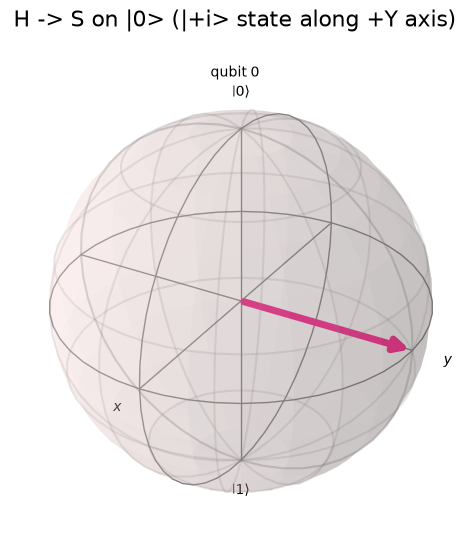

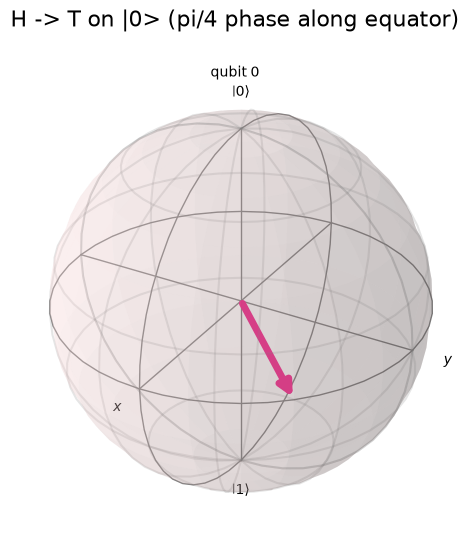

In [6]:
# Render Bloch sphere for |+i> = S|+>
from IPython.display import display
fig_s = plot_bloch_multivector(sv_s, title="H -> S on |0> (|+i> state along +Y axis)")
display(fig_s)

# Render Bloch sphere for T|+>
fig_t = plot_bloch_multivector(sv_t, title="H -> T on |0> (pi/4 phase along equator)")
display(fig_t)

## 4. Group C — Continuous Rotation Gates ($R_X, R_Y, R_Z$) & QAOA Connection

### Mathematical Definitions of Continuous Rotation Gates:
Single-qubit rotation gates are generated by exponentiating the Pauli matrices:
$$R_X(\theta) = \exp\left(-i\frac{\theta}{2}X\right) = \begin{pmatrix} \cos\frac{\theta}{2} & -i\sin\frac{\theta}{2} \\ -i\sin\frac{\theta}{2} & \cos\frac{\theta}{2} \end{pmatrix}$$
$$R_Y(\theta) = \exp\left(-i\frac{\theta}{2}Y\right) = \begin{pmatrix} \cos\frac{\theta}{2} & -\sin\frac{\theta}{2} \\ \sin\frac{\theta}{2} & \cos\frac{\theta}{2} \end{pmatrix}$$
$$R_Z(\theta) = \exp\left(-i\frac{\theta}{2}Z\right) = \begin{pmatrix} e^{-i\theta/2} & 0 \\ 0 & e^{i\theta/2} \end{pmatrix}$$

### Experiment C1: $R_Y(\pi/3)$ on $|0\rangle$
**Analytical Derivation:**
For rotation angle $\theta = \pi/3$, the half-angle is $\theta/2 = \pi/6$ ($30^\circ$):
$$R_Y(\pi/3)|0\rangle = \cos(\pi/6)|0\rangle + \sin(\pi/6)|1\rangle = \frac{\sqrt{3}}{2}|0\rangle + \frac{1}{2}|1\rangle$$
Squaring the real amplitudes yields the exact analytical measurement probabilities:
$$P(|0\rangle) = \cos^2(\pi/6) = \left(\frac{\sqrt{3}}{2}\right)^2 = \frac{3}{4} = 0.75 \quad (75\%)$$
$$P(|1\rangle) = \sin^2(\pi/6) = \left(\frac{1}{2}\right)^2 = \frac{1}{4} = 0.25 \quad (25\%)$$

**Prediction Check:**
- Exact analytical probabilities: $P(|0\rangle) = 0.75$, $P(|1\rangle) = 0.25$.
- 4096-shot Aer simulation expectation:
  - Counts for `'0'`: $4096 \times 0.75 = 3072$ counts.
  - Counts for `'1'`: $4096 \times 0.25 = 1024$ counts.

In [7]:
# Experiment C1: RY(pi/3) on |0>
qc_ry = QuantumCircuit(1)
qc_ry.ry(np.pi / 3, 0)  # Apply continuous Y-rotation of pi/3

print("=== Experiment C1: RY(pi/3) on |0> ===")
sv_ry, counts_ry = inspect_gate(qc_ry)

# Verify analytical probabilities
assert np.isclose(sv_ry.probabilities_dict()['0'], 0.75), "Exact P(0) must equal 0.75"
assert np.isclose(sv_ry.probabilities_dict()['1'], 0.25), "Exact P(1) must equal 0.25"
assert abs(counts_ry.get('0', 0) / 4096 - 0.75) < 0.03, "Sampled P(0) must be within 3% of 0.75"
assert abs(counts_ry.get('1', 0) / 4096 - 0.25) < 0.03, "Sampled P(1) must be within 3% of 0.25"
print("\nExperiment C1 Check: PASS (Analytical 0.75/0.25 verified against 4096-shot Aer)")

=== Experiment C1: RY(pi/3) on |0> ===
Exact Statevector amplitudes:
  |0>: +0.8660 + +0.0000j  (|amp|: 0.8660)
  |1>: +0.5000 + +0.0000j  (|amp|: 0.5000)

State    | Exact Prob   | Sampled Prob (4096)    | Diff      
----------------------------------------------------------
|0>    | 0.7500       | 0.7527                 | 0.0027    
|1>    | 0.2500       | 0.2473                 | 0.0027    

Experiment C1 Check: PASS (Analytical 0.75/0.25 verified against 4096-shot Aer)


### Experiment C2: $H \to R_Z(\pi/3)$ and $R_X(\pi/3)$ on $|0\rangle$
**Mathematical Action:**
1. **$H \to R_Z(\pi/3)$ on $|0\rangle$:**
   $$|0\rangle \xrightarrow{H} \frac{|0\rangle + |1\rangle}{\sqrt{2}} \xrightarrow{R_Z(\pi/3)} \frac{e^{-i\pi/6}|0\rangle + e^{i\pi/6}|1\rangle}{\sqrt{2}}$$
   The rotation adjusts the equatorial phase by $\pi/3$. The measurement probabilities remain:
   $$P(|0\rangle) = \left|\frac{e^{-i\pi/6}}{\sqrt{2}}\right|^2 = 0.5, \quad P(|1\rangle) = \left|\frac{e^{i\pi/6}}{\sqrt{2}}\right|^2 = 0.5$$
2. **$R_X(\pi/3)$ on $|0\rangle$:**
   $$R_X(\pi/3)|0\rangle = \cos(\pi/6)|0\rangle - i\sin(\pi/6)|1\rangle = \frac{\sqrt{3}}{2}|0\rangle - \frac{i}{2}|1\rangle$$
   Measurement probabilities:
   $$P(|0\rangle) = \left|\frac{\sqrt{3}}{2}\right|^2 = \frac{3}{4} = 0.75, \quad P(|1\rangle) = \left|-\frac{i}{2}\right|^2 = \frac{1}{4} = 0.25$$

**Prediction Check:**
- Circuit $H \to R_Z(\pi/3)$: Exact $P(|0\rangle) = 0.5$, $P(|1\rangle) = 0.5$.
- Circuit $R_X(\pi/3)$: Exact $P(|0\rangle) = 0.75$, $P(|1\rangle) = 0.25$.

In [8]:
# Experiment C2a: H -> RZ(pi/3) on |0>
qc_rz = QuantumCircuit(1)
qc_rz.h(0)
qc_rz.rz(np.pi / 3, 0)  # Apply Z-rotation of pi/3 to |+>
print("=== Experiment C2a: H -> RZ(pi/3) on |0> ===")
sv_rz, counts_rz = inspect_gate(qc_rz)

# Experiment C2b: RX(pi/3) on |0>
qc_rx = QuantumCircuit(1)
qc_rx.rx(np.pi / 3, 0)  # Apply X-rotation of pi/3 to |0>
print("\n=== Experiment C2b: RX(pi/3) on |0> ===")
sv_rx, counts_rx = inspect_gate(qc_rx)

# Assertions
assert np.isclose(sv_rz.probabilities_dict()['0'], 0.5), "RZ on |+> maintains 50/50 Z-basis probabilities"
assert np.isclose(sv_rx.probabilities_dict()['0'], 0.75), "RX(pi/3) on |0> yields P(0)=0.75"
assert np.isclose(sv_rx.probabilities_dict()['1'], 0.25), "RX(pi/3) on |0> yields P(1)=0.25"
print("\nExperiment C2 Check: PASS (RZ phase shift and RX rotation verified)")

=== Experiment C2a: H -> RZ(pi/3) on |0> ===
Exact Statevector amplitudes:
  |0>: +0.6124 + -0.3536j  (|amp|: 0.7071)
  |1>: +0.6124 + +0.3536j  (|amp|: 0.7071)

State    | Exact Prob   | Sampled Prob (4096)    | Diff      
----------------------------------------------------------
|0>    | 0.5000       | 0.4937                 | 0.0063    
|1>    | 0.5000       | 0.5063                 | 0.0063    

=== Experiment C2b: RX(pi/3) on |0> ===
Exact Statevector amplitudes:
  |0>: +0.8660 + +0.0000j  (|amp|: 0.8660)
  |1>: +0.0000 + -0.5000j  (|amp|: 0.5000)

State    | Exact Prob   | Sampled Prob (4096)    | Diff      
----------------------------------------------------------
|0>    | 0.7500       | 0.7527                 | 0.0027    
|1>    | 0.2500       | 0.2473                 | 0.0027    

Experiment C2 Check: PASS (RZ phase shift and RX rotation verified)


### The QAOA Connection: $R_Z$ and $R_X$ as Algorithmic Building Blocks
In the Quantum Approximate Optimization Algorithm (QAOA) for combinatorial optimization problems like Max-Cut (Farhi et al., 2014):

1. **Cost Hamiltonian Unitary $U(C, \gamma) = e^{-i\gamma C}$:**
   The Max-Cut problem on graph $G=(V, E)$ is encoded into the Ising cost Hamiltonian:
   $$C = \sum_{(j, k) \in E} \frac{1}{2}(I - Z_j Z_k)$$
   The two-qubit cost interaction $e^{i\frac{\gamma}{2} Z_j Z_k}$ is compiled into standard gates:
   $$CNOT(j, k) \longrightarrow R_Z(-\gamma)_k \longrightarrow CNOT(j, k)$$
   The single-qubit **$R_Z$ rotation gate** is the exact engine that applies problem-dependent phase shifts to computational basis states proportional to their edge cuts.

2. **Mixer Hamiltonian Unitary $U(B, \beta) = e^{-i\beta B}$:**
   The standard transverse-field mixer Hamiltonian is:
   $$B = \sum_{j \in V} X_j$$
   Because every single-qubit term $X_j$ acts on a distinct qubit, all terms commute ($[X_j, X_k] = 0$). Consequently, the unitary exponentiation factors without Trotterization error into independent single-qubit rotations:
   $$e^{-i\beta B} = \prod_{j \in V} e^{-i\beta X_j} = \prod_{j \in V} R_X(2\beta)_j$$
   Thus, the QAOA mixer layer is **identically a parallel bank of single-qubit $R_X(2\beta)$ rotation gates**!
   $R_X$ generates quantum superposition and tunneling between orthogonal computational basis states $|x\rangle$, driving constructive interference toward states with maximum cut values.